# Week 1 · Task 1 — Prove why we visualize

Data: `datasaurus.csv` — 1,846 rows (`dataset`, `x`, `y`): **13 datasets × 142 points**.
Rules used on every chart: title states a finding, bars start at zero, never two y-axes, colour must mean something, label selectively, excluded rows declared on the chart.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt          # only plt.subplots() is used; every chart is drawn with methods on ax
from matplotlib.ticker import FuncFormatter
from pathlib import Path

DATA = Path(r"C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 1\datasaurus.csv")                       # folder made by download_assignment_data.py
GREY, DARK = "#bbbbbb", "#444444"
COL = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "pink": "#CC79A7", "red": "#D55E00", "sky": "#56B4E9"}
mpl.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def note(fig, text, y=-0.03):
    # one-line footnote: sample size and any excluded rows are declared on the figure itself
    fig.text(0.01, y, text, fontsize=8, ha="left")

In [3]:
ds = pd.read_csv(r"C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 1\datasaurus.csv")
print(ds.shape, "| datasets:", ds["dataset"].nunique(), "| points per dataset:", ds.groupby("dataset").size().unique(), "| missing:", int(ds.isna().sum().sum()))
ds.head()

(1846, 3) | datasets: 13 | points per dataset: [142] | missing: 0


,dataset,x,y
0,dino,55.3846,97.1795
1,dino,51.5385,96.0256
2,dino,46.1538,94.4872
3,dino,42.8205,91.4103
4,dino,40.7692,88.3333


## 1. Summary statistics for all 13 datasets (one table)

In [4]:
summary = ds.groupby("dataset").agg(mean_x=("x", "mean"), mean_y=("y", "mean"), sd_x=("x", "std"), sd_y=("y", "std"))
summary["corr_xy"] = [g["x"].corr(g["y"]) for _, g in ds.groupby("dataset")]      # same (alphabetical) order as the groupby above
display(summary.round(2))
print("Largest difference between any two datasets, per statistic:")
display((summary.max() - summary.min()).round(3).to_frame("max - min").T)

,mean_x,mean_y,sd_x,sd_y,corr_xy
dataset,,,,,
away,54.27,47.83,16.77,26.94,-0.06
bullseye,54.27,47.83,16.77,26.94,-0.07
circle,54.27,47.84,16.76,26.93,-0.07
dino,54.26,47.83,16.77,26.94,-0.06
dots,54.26,47.84,16.77,26.93,-0.06
h_lines,54.26,47.83,16.77,26.94,-0.06
high_lines,54.27,47.84,16.77,26.94,-0.07
slant_down,54.27,47.84,16.77,26.94,-0.07
slant_up,54.27,47.83,16.77,26.94,-0.07


Largest difference between any two datasets, per statistic:


,mean_x,mean_y,sd_x,sd_y,corr_xy
max - min,0.01,0.01,0.01,0.01,0.009


(`sd` is the sample standard deviation, `ddof = 1`; `corr_xy` is Pearson's r.)

## 2. What I would conclude if the table were all I had

Every row says the same thing. In all 13 datasets x averages about 54 with a spread of about 17, y averages about 48 with a spread of about 27, and the correlation is about −0.06, i.e. essentially **no linear relationship**.
From the table alone I would conclude that there is one kind of data here: a shapeless cloud, wider in y than in x, with x and y unrelated. I would probably also assume the 13 datasets were 13 random samples from the same population.

## 3. Plot all 13 as a grid of scatter plots

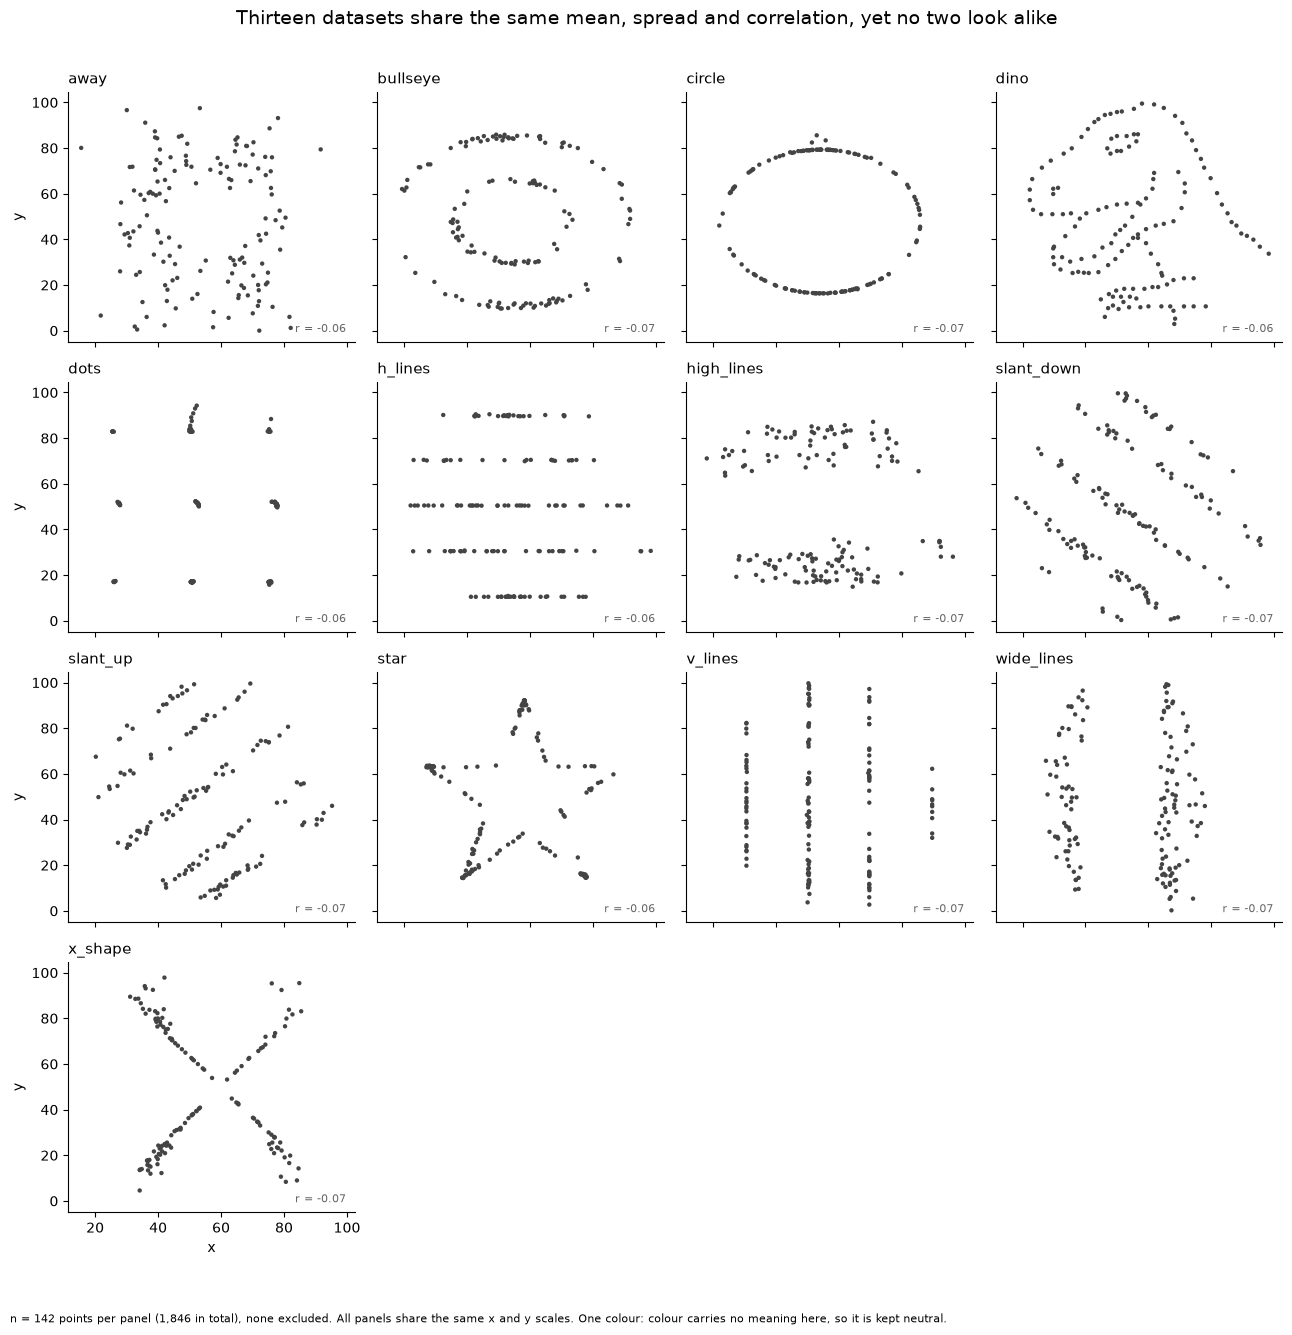

In [5]:
names = sorted(ds["dataset"].unique())
fig, axes = plt.subplots(4, 4, figsize=(13, 13), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), names):
    d = ds[ds["dataset"] == name]
    ax.scatter(d["x"], d["y"], s=10, color=DARK, edgecolors="none")
    ax.set_title(name, fontsize=11, loc="left")
    ax.text(0.97, 0.04, f"r = {d['x'].corr(d['y']):.2f}", transform=ax.transAxes, ha="right", fontsize=8, color="#666666")
for ax in axes.ravel()[len(names):]:
    ax.set_axis_off()                                    # 13 panels in a 4x4 grid: hide the three spare ones
for ax in axes[-1, :]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("y")
fig.suptitle("Thirteen datasets share the same mean, spread and correlation, yet no two look alike", fontsize=14)
note(fig, "n = 142 points per panel (1,846 in total), none excluded. All panels share the same x and y scales. One colour: colour carries no meaning here, so it is kept neutral.")
fig.tight_layout(rect=(0, 0.01, 1, 0.97))
fig.savefig("w1_task1_grid.png", dpi=200, bbox_inches="tight")

**Why this chart type.** I need to compare the *shape* of 13 two-variable datasets, so each gets a scatter plot (x and y are both numeric and I want to see every point), and small multiples (a grid) put them side by side. Shared axes make the panels directly comparable, and I used a single neutral colour because nothing needs to be distinguished by colour.
Each panel is labelled with its name, and the correlation is repeated in a small, quiet caption to make the point that it never changes.

## 4. What I actually found

The identical numbers hide completely different structures: `dino` is a dinosaur, `star` is a star, `circle` and `bullseye` are rings, `x_shape` is an X, `h_lines` and `v_lines` are stripes, `slant_up` and `slant_down` are tilted bands, `dots` is a grid of clusters, `away` and `wide_lines` and `high_lines` are other arrangements.
Several of them show strong *non-linear* or clustered structure, which Pearson's r (a measure of straight-line association) cannot see. Mean and standard deviation only say where the cloud is centred and how wide it is, not what it looks like. The conclusion I drew from the table in step 2 — "a shapeless cloud, one population" — is wrong for almost every dataset.

## The question: do 13 datasets and 142 points make summary statistics more trustworthy?

In [6]:
sd_x = ds["x"].std()
for n in (11, 142):
    print(f"n = {n:>3}: standard error of the mean of x ~ sd/sqrt(n) = {sd_x:.1f}/sqrt({n}) = {sd_x/np.sqrt(n):.1f}")

n =  11: standard error of the mean of x ~ sd/sqrt(n) = 16.7/sqrt(11) = 5.0
n = 142: standard error of the mean of x ~ sd/sqrt(n) = 16.7/sqrt(142) = 1.4


**Short answer: no — more data makes the numbers *more precise*, but not *more meaningful*.**

- Going from 11 to 142 points shrinks the sampling error of each statistic (the standard error of the mean of x falls from about 5.1 to about 1.4, see above). So each of the five numbers is a better estimate of its true value.
- But the problem in Anscombe's quartet was never sampling noise; it was **information loss**. Five summary numbers cannot describe 284 numbers (142 × 2) whose arrangement matters. Many different pictures share the same mean, spread and correlation, whether there are 11 points or 142.
- Having 13 datasets makes it *worse for the table and better for the argument*: the table looks even more convincing (13 identical rows!) while the grid shows 13 different pictures. These datasets were deliberately engineered to match to two decimals, so real data would not match this perfectly, but the lesson is the same.

**Conclusion:** summary statistics are a useful second step, never the first one. Always plot the data first, because a chart shows the shape that the statistics throw away.